In [41]:
%pip install -q ultralytics opencv-python torch torchvision numpy pandas matplotlib seaborn pillow tqdm pyyaml

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

from ultralytics import YOLO
import ultralytics

In [43]:
plt.style.use("ggplot")
sns.set_palette("husl")

In [44]:
if torch.cuda.is_available():
    DEVICE = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Selected Device:", DEVICE)

Selected Device: mps


In [45]:
BASE_DIR = Path.cwd()

DATA_DIR = BASE_DIR / "data"
DATASET_DIR = DATA_DIR / "datasets"
OUTPUT_DIR = DATA_DIR / "output_videos"
MODEL_DIR = BASE_DIR / "models"

for directory in [DATASET_DIR, OUTPUT_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project directories created successfully!")

print("Dataset Directory:", DATASET_DIR)
print("Output Directory:", OUTPUT_DIR)
print("Model Directory:", MODEL_DIR)

Project directories created successfully!
Dataset Directory: /Users/varshh06/Desktop/CV-END-TO-END/01-REAL-TIME-OBJECT-DETECTION-AND-TRACKING/data/datasets
Output Directory: /Users/varshh06/Desktop/CV-END-TO-END/01-REAL-TIME-OBJECT-DETECTION-AND-TRACKING/data/output_videos
Model Directory: /Users/varshh06/Desktop/CV-END-TO-END/01-REAL-TIME-OBJECT-DETECTION-AND-TRACKING/models


In [46]:
MODEL_NAME = "yolo11n.pt"

model = YOLO(MODEL_NAME)

print("YOLO model loaded successfully!")

print("Model:", MODEL_NAME)
print("Device:", DEVICE)

YOLO model loaded successfully!
Model: yolo11n.pt
Device: mps


In [47]:
class_names = model.names

print("Total Object Classes:", len(class_names))

for class_id, class_name in class_names.items():
    print(f"{class_id}: {class_name}")

Total Object Classes: 80
0: person
1: bicycle
2: car
3: motorcycle
4: airplane
5: bus
6: train
7: truck
8: boat
9: traffic light
10: fire hydrant
11: stop sign
12: parking meter
13: bench
14: bird
15: cat
16: dog
17: horse
18: sheep
19: cow
20: elephant
21: bear
22: zebra
23: giraffe
24: backpack
25: umbrella
26: handbag
27: tie
28: suitcase
29: frisbee
30: skis
31: snowboard
32: sports ball
33: kite
34: baseball bat
35: baseball glove
36: skateboard
37: surfboard
38: tennis racket
39: bottle
40: wine glass
41: cup
42: fork
43: knife
44: spoon
45: bowl
46: banana
47: apple
48: sandwich
49: orange
50: broccoli
51: carrot
52: hot dog
53: pizza
54: donut
55: cake
56: chair
57: couch
58: potted plant
59: bed
60: dining table
61: toilet
62: tv
63: laptop
64: mouse
65: remote
66: keyboard
67: cell phone
68: microwave
69: oven
70: toaster
71: sink
72: refrigerator
73: book
74: clock
75: vase
76: scissors
77: teddy bear
78: hair drier
79: toothbrush


In [48]:
IMAGE_URL = "https://ultralytics.com/images/bus.jpg"

results = model.predict(
    source=IMAGE_URL,
    conf=0.25,
    device=DEVICE,
    verbose=False
)

print("Object detection completed!")

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Object detection completed!


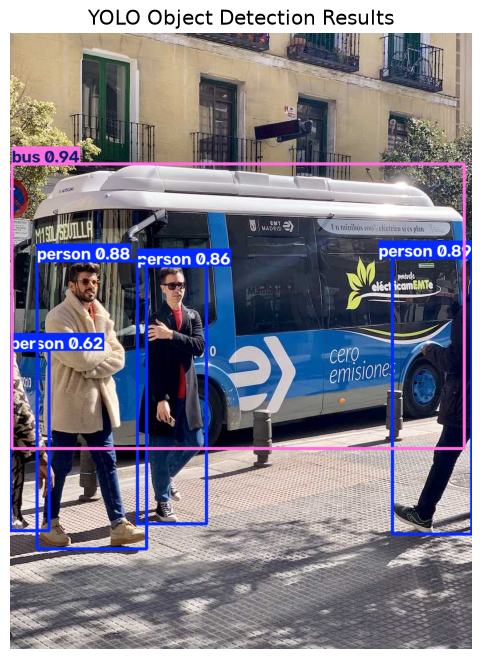

In [49]:
result = results[0]

annotated_image = result.plot()

# Convert BGR to RGB
annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))

plt.imshow(annotated_image)
plt.title("YOLO Object Detection Results")
plt.axis("off")
plt.show()

In [50]:
detections = []

for box in result.boxes:

    class_id = int(box.cls[0])

    confidence = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    detections.append({
        "Object": class_names[class_id],
        "Confidence": round(confidence, 4),
        "X1": round(float(x1), 2),
        "Y1": round(float(y1), 2),
        "X2": round(float(x2), 2),
        "Y2": round(float(y2), 2)
    })

detection_df = pd.DataFrame(detections)

display(detection_df)


,Object,Confidence,X1,Y1,X2,Y2
0,bus,0.9404,3.80,229.38,796.23,728.35
1,person,0.8884,670.97,394.89,809.81,878.69
2,person,0.8788,47.43,399.57,239.42,904.19
3,person,0.8564,223.08,408.72,344.49,860.41
4,person,0.6235,0.02,556.09,68.77,872.33


In [51]:

if not detection_df.empty:

    print("TOTAL OBJECTS DETECTED:",
          len(detection_df))

    print("\nOBJECT CATEGORY COUNTS:")

    print(
        detection_df["Object"].value_counts()
    )

    print("\nAVERAGE CONFIDENCE:")

    print(
        round(detection_df["Confidence"].mean(), 4)
    )

else:
    print("No objects detected.")


TOTAL OBJECTS DETECTED: 5

OBJECT CATEGORY COUNTS:
Object
person    4
bus       1
Name: count, dtype: int64

AVERAGE CONFIDENCE:
0.8375


In [52]:
cap = cv2.VideoCapture(0)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Webcam initialized successfully!")

Webcam initialized successfully!


In [53]:
import time

CONFIDENCE_THRESHOLD = 0.40

print("Starting real-time object detection...")
print("Press Q to stop the webcam.")

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        print("Unable to read webcam frame.")
        break

    start_time = time.time()
    results = model.predict(
        source=frame,
        conf=CONFIDENCE_THRESHOLD,
        device=DEVICE,
        verbose=False
    )

    result = results[0]
    annotated_frame = result.plot()
    elapsed_time = time.time() - start_time
    fps = 1 / elapsed_time if elapsed_time > 0 else 0

    cv2.putText(
        annotated_frame,
        f"FPS: {fps:.2f}",
        (20, 35),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

    object_count = len(result.boxes)
    cv2.putText(
        annotated_frame,
        f"Objects: {object_count}",
        (20, 70),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

    cv2.imshow(
        "REAL-TIME OBJECT DETECTION",
        annotated_frame
    )
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

print("Webcam detection stopped successfully!")

Starting real-time object detection...
Press Q to stop the webcam.
Webcam detection stopped successfully!


In [54]:
cap.release()
cv2.destroyAllWindows()

print("Camera resources released!")

Camera resources released!


In [55]:
TRACKER_CONFIG = "bytetrack.yaml"

TRACK_CONFIDENCE = 0.35

TRACK_CLASSES = None  # Track all detected classes

print("Tracking Configuration")
print("Tracker:", TRACKER_CONFIG)
print("Confidence Threshold:", TRACK_CONFIDENCE)
print("Device:", DEVICE)

Tracking Configuration
Tracker: bytetrack.yaml
Confidence Threshold: 0.35
Device: mps


In [56]:
cap = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Webcam ready for object tracking!")


Webcam ready for object tracking!


In [57]:
import time

print("Starting YOLO + ByteTrack...")
print("Press Q to stop tracking.")

try:

    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Frame capture failed!")
            break

        start_time = time.time()

        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=TRACK_CONFIDENCE,
            classes=TRACK_CLASSES,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        if result.boxes.id is not None:

            track_ids = (
                result.boxes.id.int().cpu().tolist()
            )

            object_count = len(track_ids)

        else:

            track_ids = []
            object_count = 0

        elapsed = time.time() - start_time

        fps = 1 / elapsed if elapsed > 0 else 0
        cv2.putText(
            annotated_frame,
            f"FPS: {fps:.2f}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"Tracked Objects: {object_count}",
            (20, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        cv2.imshow(
            "YOLO + BYTETRACK",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:

    cap.release()
    cv2.destroyAllWindows()

    print("Tracking stopped successfully!")


Starting YOLO + ByteTrack...
Press Q to stop tracking.


Tracking stopped successfully!


In [58]:
from collections import deque

track_history = {}

frame_number = 0
MAX_TRACK_HISTORY = 50

print("Tracking history initialized!")

Tracking history initialized!


In [59]:
import time

cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Starting object tracking with ID management...")
print("Press Q to stop.")

try:
    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Unable to read webcam frame.")
            break

        frame_number += 1
        start_time = time.time()

        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=TRACK_CONFIDENCE,
            classes=TRACK_CLASSES,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        current_ids = []

        if result.boxes.id is not None:

            track_ids = result.boxes.id.int().cpu().tolist()
            class_ids = result.boxes.cls.int().cpu().tolist()
            boxes = result.boxes.xyxy.cpu().numpy()

            for track_id, class_id, box in zip(
                track_ids, class_ids, boxes
            ):

                x1, y1, x2, y2 = map(int, box)

                center_x = (x1 + x2) // 2
                center_y = (y1 + y2) // 2

                center = (center_x, center_y)

                class_name = model.names[class_id]

                current_ids.append(track_id)

                if track_id not in track_history:

                    track_history[track_id] = {
                        "class_name": class_name,
                        "first_seen_frame": frame_number,
                        "last_seen_frame": frame_number,
                        "frames_tracked": 0,
                        "positions": deque(
                            maxlen=MAX_TRACK_HISTORY
                        )
                    }

                history = track_history[track_id]

                history["last_seen_frame"] = frame_number
                history["frames_tracked"] += 1
                history["positions"].append(center)

                cv2.circle(
                    annotated_frame,
                    center,
                    5,
                    (0, 255, 255),
                    -1
                )

                cv2.putText(
                    annotated_frame,
                    f"ID: {track_id} | {class_name}",
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 255),
                    2
                )

        elapsed_time = time.time() - start_time
        fps = 1 / elapsed_time if elapsed_time > 0 else 0

        cv2.putText(
            annotated_frame,
            f"FPS: {fps:.2f}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"Active Objects: {len(current_ids)}",
            (20, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"Total IDs Observed: {len(track_history)}",
            (20, 105),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        cv2.imshow(
            "OBJECT TRACKING - ID MANAGEMENT",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

    print("Tracking stopped!")

Starting object tracking with ID management...
Press Q to stop.
Tracking stopped!


In [60]:
import pandas as pd

tracking_records = []

for track_id, history in track_history.items():

    tracking_records.append({
        "Tracking ID": track_id,
        "Object Class": history["class_name"],
        "First Seen Frame": history["first_seen_frame"],
        "Last Seen Frame": history["last_seen_frame"],
        "Frames Tracked": history["frames_tracked"],
        "Recent Positions": len(history["positions"])
    })

tracking_df = pd.DataFrame(tracking_records)

tracking_df

,Tracking ID,Object Class,First Seen Frame,Last Seen Frame,Frames Tracked,Recent Positions
0,1,person,2,134,132,50
1,6,person,434,2500,2042,50
2,11,person,458,477,2,2
3,17,person,575,578,3,3
4,23,person,641,671,24,24
5,27,person,710,819,16,16
6,40,person,986,1032,7,7
7,44,surfboard,1036,1036,1,1
8,52,person,1096,1096,1,1
9,54,cell phone,1594,1594,1,1


In [61]:
from collections import Counter

object_class_counts = Counter()
unique_object_ids = set()

print("Object counting initialized!")

Object counting initialized!


In [62]:
import time

cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Starting real-time object counting...")
print("Press Q to stop.")

try:
    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Unable to read webcam frame.")
            break

        start_time = time.time()

        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=TRACK_CONFIDENCE,
            classes=TRACK_CLASSES,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        current_counts = Counter()
        current_ids = set()

        if result.boxes.id is not None:

            track_ids = result.boxes.id.int().cpu().tolist()
            class_ids = result.boxes.cls.int().cpu().tolist()

            for track_id, class_id in zip(track_ids, class_ids):

                class_name = model.names[class_id]

                current_counts[class_name] += 1
                current_ids.add(track_id)
                unique_object_ids.add(track_id)

        # Calculate FPS
        elapsed_time = time.time() - start_time
        fps = 1 / elapsed_time if elapsed_time > 0 else 0

        # Display total visible objects
        cv2.putText(
            annotated_frame,
            f"Visible Objects: {len(current_ids)}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        # Display unique objects
        cv2.putText(
            annotated_frame,
            f"Unique IDs: {len(unique_object_ids)}",
            (20, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        # Display class-wise counts
        y_position = 110

        for class_name, count in current_counts.items():

            cv2.putText(
                annotated_frame,
                f"{class_name}: {count}",
                (20, y_position),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 255),
                2
            )

            y_position += 25

        cv2.putText(
            annotated_frame,
            f"FPS: {fps:.2f}",
            (20, y_position + 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 255, 0),
            2
        )

        cv2.imshow(
            "REAL-TIME OBJECT COUNTING",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

    print("Object counting stopped!")

Starting real-time object counting...
Press Q to stop.
Object counting stopped!


In [63]:
print("OBJECT COUNTING SUMMARY")
print("Total unique tracking IDs:", len(unique_object_ids))

print("\nTracking history by object class:")

for class_name in sorted({
    history["class_name"]
    for history in track_history.values()
}):
    count = sum(
        1 for history in track_history.values()
        if history["class_name"] == class_name
    )

    print(f"{class_name}: {count}")

OBJECT COUNTING SUMMARY
Total unique tracking IDs: 5

Tracking history by object class:
book: 1
cell phone: 1
frisbee: 1
person: 9
surfboard: 1


In [64]:
FRAME_WIDTH = 640
FRAME_HEIGHT = 480

LINE_X = FRAME_WIDTH // 2

left_to_right_count = 0
right_to_left_count = 0

previous_positions = {}
counted_crossings = set()

print("Virtual line configured at:", LINE_X)

Virtual line configured at: 320


In [65]:
import time

cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, FRAME_WIDTH)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, FRAME_HEIGHT)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Starting line crossing detection...")
print("Press Q to stop.")

try:
    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Unable to read webcam frame.")
            break

        start_time = time.time()

        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=TRACK_CONFIDENCE,
            classes=TRACK_CLASSES,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        cv2.line(
            annotated_frame,
            (LINE_X, 0),
            (LINE_X, FRAME_HEIGHT),
            (255, 0, 255),
            2
        )

        if result.boxes.id is not None:

            track_ids = result.boxes.id.int().cpu().tolist()
            boxes = result.boxes.xyxy.cpu().numpy()

            for track_id, box in zip(track_ids, boxes):

                x1, y1, x2, y2 = map(int, box)

                center_x = (x1 + x2) // 2
                center_y = (y1 + y2) // 2

                current_side = "left" if center_x < LINE_X else "right"

                if track_id in previous_positions:

                    previous_side = previous_positions[track_id]

                    crossing_key = (track_id, previous_side, current_side)

                    if previous_side != current_side and crossing_key not in counted_crossings:

                        if previous_side == "left" and current_side == "right":
                            left_to_right_count += 1

                        elif previous_side == "right" and current_side == "left":
                            right_to_left_count += 1

                        counted_crossings.add(crossing_key)

                previous_positions[track_id] = current_side

                cv2.circle(
                    annotated_frame,
                    (center_x, center_y),
                    5,
                    (0, 255, 255),
                    -1
                )

        elapsed_time = time.time() - start_time
        fps = 1 / elapsed_time if elapsed_time > 0 else 0

        cv2.putText(
            annotated_frame,
            f"Left to Right: {left_to_right_count}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"Right to Left: {right_to_left_count}",
            (20, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"Total Crossings: {left_to_right_count + right_to_left_count}",
            (20, 105),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 255),
            2
        )

        cv2.putText(
            annotated_frame,
            f"FPS: {fps:.2f}",
            (20, 140),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (255, 255, 0),
            2
        )

        cv2.imshow(
            "LINE CROSSING DETECTION",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

    print("Line crossing detection stopped!")
    print("Left to Right:", left_to_right_count)
    print("Right to Left:", right_to_left_count)

Starting line crossing detection...
Press Q to stop.
Line crossing detection stopped!
Left to Right: 1
Right to Left: 1


In [66]:
from collections import defaultdict, deque

trajectory_history = defaultdict(
    lambda: deque(maxlen=40)
)

TRAJECTORY_LENGTH = 40

print("Trajectory storage initialized!")

Trajectory storage initialized!


In [67]:
import time

cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, FRAME_WIDTH)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, FRAME_HEIGHT)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Starting trajectory visualization...")
print("Press Q to stop.")

try:
    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Unable to read webcam frame.")
            break

        start_time = time.time()

        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=TRACK_CONFIDENCE,
            classes=TRACK_CLASSES,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        if result.boxes.id is not None:

            track_ids = result.boxes.id.int().cpu().tolist()
            boxes = result.boxes.xyxy.cpu().numpy()

            for track_id, box in zip(track_ids, boxes):

                x1, y1, x2, y2 = map(int, box)

                center_x = (x1 + x2) // 2
                center_y = (y1 + y2) // 2

                center = (center_x, center_y)

                # Store object position
                trajectory_history[track_id].append(center)

                # Draw trajectory
                points = list(trajectory_history[track_id])

                for i in range(1, len(points)):

                    cv2.line(
                        annotated_frame,
                        points[i - 1],
                        points[i],
                        (0, 255, 255),
                        2
                    )

                # Draw current object center
                cv2.circle(
                    annotated_frame,
                    center,
                    5,
                    (0, 0, 255),
                    -1
                )

                cv2.putText(
                    annotated_frame,
                    f"ID: {track_id}",
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 255),
                    2
                )

        elapsed_time = time.time() - start_time
        fps = 1 / elapsed_time if elapsed_time > 0 else 0

        cv2.putText(
            annotated_frame,
            f"FPS: {fps:.2f}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"Tracked Objects: {len(trajectory_history)}",
            (20, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        cv2.imshow(
            "OBJECT TRAJECTORY VISUALIZATION",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

    print("Trajectory visualization stopped!")

Starting trajectory visualization...
Press Q to stop.
Trajectory visualization stopped!


In [68]:
print("OBJECT TRAJECTORY SUMMARY")

for track_id, positions in trajectory_history.items():

    print(
        f"ID {track_id}: "
        f"{len(positions)} recent positions recorded"
    )

OBJECT TRAJECTORY SUMMARY
ID 6: 40 recent positions recorded


In [69]:
FRAME_WIDTH = 640
FRAME_HEIGHT = 480

ZONE_X1 = 180
ZONE_Y1 = 100
ZONE_X2 = 460
ZONE_Y2 = 400

previous_zone_status = {}
zone_entry_count = 0
zone_exit_count = 0

print("Monitoring zone configured!")

Monitoring zone configured!


In [70]:
import time

cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, FRAME_WIDTH)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, FRAME_HEIGHT)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Starting zone monitoring...")
print("Press Q to stop.")

try:
    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Unable to read webcam frame.")
            break

        start_time = time.time()

        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=TRACK_CONFIDENCE,
            classes=TRACK_CLASSES,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        # Draw monitoring zone
        cv2.rectangle(
            annotated_frame,
            (ZONE_X1, ZONE_Y1),
            (ZONE_X2, ZONE_Y2),
            (255, 0, 255),
            2
        )

        cv2.putText(
            annotated_frame,
            "MONITORING ZONE",
            (ZONE_X1, ZONE_Y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 255),
            2
        )

        current_zone_ids = set()

        if result.boxes.id is not None:

            track_ids = result.boxes.id.int().cpu().tolist()
            boxes = result.boxes.xyxy.cpu().numpy()

            for track_id, box in zip(track_ids, boxes):

                x1, y1, x2, y2 = map(int, box)

                # Calculate object center
                center_x = (x1 + x2) // 2
                center_y = (y1 + y2) // 2

                # Check whether center is inside zone
                inside_zone = (
                    ZONE_X1 <= center_x <= ZONE_X2
                    and ZONE_Y1 <= center_y <= ZONE_Y2
                )

                if inside_zone:
                    current_zone_ids.add(track_id)

                was_inside = previous_zone_status.get(
                    track_id, False
                )

                # Detect zone entry
                if inside_zone and not was_inside:
                    zone_entry_count += 1

                # Detect zone exit
                elif was_inside and not inside_zone:
                    zone_exit_count += 1

                previous_zone_status[track_id] = inside_zone

                # Display zone status
                status = "INSIDE" if inside_zone else "OUTSIDE"

                cv2.putText(
                    annotated_frame,
                    f"ID {track_id}: {status}",
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 255),
                    2
                )

        # Calculate FPS
        elapsed_time = time.time() - start_time
        fps = 1 / elapsed_time if elapsed_time > 0 else 0

        # Display monitoring statistics
        cv2.putText(
            annotated_frame,
            f"Objects Inside Zone: {len(current_zone_ids)}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"Total Entries: {zone_entry_count}",
            (20, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"Total Exits: {zone_exit_count}",
            (20, 105),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            f"FPS: {fps:.2f}",
            (20, 140),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (255, 255, 0),
            2
        )

        cv2.imshow(
            "REAL-TIME ZONE MONITORING",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

    print("Zone monitoring stopped!")
    print("Total entries:", zone_entry_count)
    print("Total exits:", zone_exit_count)

Starting zone monitoring...
Press Q to stop.
Zone monitoring stopped!
Total entries: 2
Total exits: 0


In [71]:
print("ZONE MONITORING SUMMARY")

print("Total zone entries:", zone_entry_count)
print("Total zone exits:", zone_exit_count)

print(
    "Currently inside zone:",
    sum(previous_zone_status.values())
)

ZONE MONITORING SUMMARY
Total zone entries: 2
Total zone exits: 0
Currently inside zone: 2


In [72]:
import time

speed_history = {}

SPEED_THRESHOLD = 20  # pixels per second

print("Speed estimation initialized!")

Speed estimation initialized!


In [73]:
cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, FRAME_WIDTH)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, FRAME_HEIGHT)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Starting real-time speed estimation...")
print("Press Q to stop.")

try:
    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Unable to read webcam frame.")
            break

        current_time = time.perf_counter()

        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=TRACK_CONFIDENCE,
            classes=TRACK_CLASSES,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        if result.boxes.id is not None:

            track_ids = result.boxes.id.int().cpu().tolist()
            boxes = result.boxes.xyxy.cpu().numpy()

            for track_id, box in zip(track_ids, boxes):

                x1, y1, x2, y2 = map(int, box)

                center_x = (x1 + x2) // 2
                center_y = (y1 + y2) // 2

                current_position = (center_x, center_y)

                speed = 0.0

                if track_id in speed_history:

                    previous_position, previous_time = (
                        speed_history[track_id]
                    )

                    elapsed_time = current_time - previous_time

                    if elapsed_time > 0:

                        displacement = (
                            (center_x - previous_position[0]) ** 2
                            + (center_y - previous_position[1]) ** 2
                        ) ** 0.5

                        speed = displacement / elapsed_time

                speed_history[track_id] = (
                    current_position,
                    current_time
                )

                movement_status = (
                    "MOVING"
                    if speed >= SPEED_THRESHOLD
                    else "STATIONARY"
                )

                cv2.putText(
                    annotated_frame,
                    f"ID {track_id}: {speed:.1f} px/s",
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 255),
                    2
                )

                cv2.putText(
                    annotated_frame,
                    movement_status,
                    (x1, y2 + 20),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 0) if movement_status == "MOVING"
                    else (255, 255, 0),
                    2
                )

        cv2.imshow(
            "REAL-TIME SPEED ESTIMATION",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

    print("Speed estimation stopped!")

Starting real-time speed estimation...
Press Q to stop.
Speed estimation stopped!


In [74]:
from collections import Counter
import time

analytics_unique_ids = set()
analytics_speed_state = {}
analytics_class_counts = Counter()

analytics_frame_count = 0
analytics_total_fps = 0.0

print("Real-time analytics initialized!")

Real-time analytics initialized!


In [75]:
cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, FRAME_WIDTH)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, FRAME_HEIGHT)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Starting real-time analytics dashboard...")
print("Press Q to stop.")

try:
    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Unable to read webcam frame.")
            break

        start_time = time.perf_counter()

        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=TRACK_CONFIDENCE,
            classes=TRACK_CLASSES,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        current_counts = Counter()
        current_speeds = []

        active_ids = set()

        if result.boxes.id is not None:

            track_ids = result.boxes.id.int().cpu().tolist()
            class_ids = result.boxes.cls.int().cpu().tolist()
            boxes = result.boxes.xyxy.cpu().numpy()

            current_time = time.perf_counter()

            for track_id, class_id, box in zip(
                track_ids, class_ids, boxes
            ):

                x1, y1, x2, y2 = map(int, box)

                class_name = model.names[class_id]

                center = (
                    (x1 + x2) // 2,
                    (y1 + y2) // 2
                )

                active_ids.add(track_id)
                analytics_unique_ids.add(track_id)
                current_counts[class_name] += 1

                # Calculate approximate movement speed
                speed = 0.0

                if track_id in analytics_speed_state:

                    previous_position, previous_time = (
                        analytics_speed_state[track_id]
                    )

                    elapsed = current_time - previous_time

                    if elapsed > 0:

                        dx = center[0] - previous_position[0]
                        dy = center[1] - previous_position[1]

                        displacement = (dx**2 + dy**2) ** 0.5

                        speed = displacement / elapsed

                analytics_speed_state[track_id] = (
                    center,
                    current_time
                )

                current_speeds.append(speed)

        # Calculate analytics
        visible_objects = len(active_ids)
        unique_objects = len(analytics_unique_ids)

        average_speed = (
            sum(current_speeds) / len(current_speeds)
            if current_speeds else 0
        )

        elapsed_time = time.perf_counter() - start_time
        fps = 1 / elapsed_time if elapsed_time > 0 else 0

        analytics_frame_count += 1
        analytics_total_fps += fps

        average_fps = (
            analytics_total_fps / analytics_frame_count
        )

        # Dashboard panel
        panel_x = 10
        panel_y = 10
        panel_width = 280
        panel_height = 230

        overlay = annotated_frame.copy()

        cv2.rectangle(
            overlay,
            (panel_x, panel_y),
            (panel_x + panel_width, panel_y + panel_height),
            (0, 0, 0),
            -1
        )

        annotated_frame = cv2.addWeighted(
            overlay, 0.65, annotated_frame, 0.35, 0
        )

        # Display main metrics
        dashboard_text = [
            "REAL-TIME ANALYTICS",
            f"Visible Objects: {visible_objects}",
            f"Unique IDs: {unique_objects}",
            f"Average Speed: {average_speed:.1f} px/s",
            f"Current FPS: {fps:.1f}",
            f"Average FPS: {average_fps:.1f}",
            "CLASS-WISE COUNTS:"
        ]

        y_position = 35

        for text_line in dashboard_text:

            cv2.putText(
                annotated_frame,
                text_line,
                (20, y_position),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2
            )

            y_position += 28

        # Display class-wise counts
        for class_name, count in current_counts.items():

            cv2.putText(
                annotated_frame,
                f"{class_name}: {count}",
                (30, y_position),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 255),
                1
            )

            y_position += 23

        cv2.imshow(
            "REAL-TIME OBJECT ANALYTICS DASHBOARD",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

    print("Analytics dashboard stopped!")

Starting real-time analytics dashboard...
Press Q to stop.
Analytics dashboard stopped!


In [76]:
print("FINAL ANALYTICS SUMMARY")

print("Total Frames Processed:", analytics_frame_count)
print("Unique Tracking IDs:", len(analytics_unique_ids))
print("Average FPS:", round(
    analytics_total_fps / analytics_frame_count, 2
) if analytics_frame_count else 0)

print("\nLast Frame Class Counts:")

for class_name, count in current_counts.items():
    print(f"{class_name}: {count}")

FINAL ANALYTICS SUMMARY
Total Frames Processed: 24
Unique Tracking IDs: 1
Average FPS: 45.25

Last Frame Class Counts:
person: 1


In [77]:
from collections import defaultdict, deque, Counter
import cv2
import time

# Frame configuration
FRAME_WIDTH = 640
FRAME_HEIGHT = 480

# Detection and tracking configuration
CONFIDENCE_THRESHOLD = 0.35
TRACKER_CONFIG = "bytetrack.yaml"

# Virtual line
LINE_X = FRAME_WIDTH // 2

# Monitoring zone
ZONE_X1 = 180
ZONE_Y1 = 100
ZONE_X2 = 460
ZONE_Y2 = 400

# Tracking history
integrated_history = {}

MAX_TRAJECTORY_LENGTH = 40

# Counting
unique_ids = set()

left_to_right_count = 0
right_to_left_count = 0

# Zone monitoring
zone_entry_count = 0
zone_exit_count = 0

# Analytics
total_frames = 0
total_fps = 0.0

print("Integrated system initialized successfully!")
print("YOLO Model:", model)
print("Tracker:", TRACKER_CONFIG)
print("Device:", DEVICE)

Integrated system initialized successfully!
YOLO Model: YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=Fal

In [78]:
cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, FRAME_WIDTH)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, FRAME_HEIGHT)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam!")

print("Integrated object detection system started!")
print("Press Q to stop the application.")

try:
    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            print("Unable to read webcam frame.")
            break

        start_time = time.perf_counter()

        frame_height, frame_width = frame.shape[:2]

        # YOLO + ByteTrack
        results = model.track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            conf=CONFIDENCE_THRESHOLD,
            device=DEVICE,
            verbose=False
        )

        result = results[0]
        annotated_frame = result.plot()

        # Current frame statistics
        current_counts = Counter()
        active_ids = set()
        current_speeds = []

        # Draw virtual line
        line_x = frame_width // 2

        cv2.line(
            annotated_frame,
            (line_x, 0),
            (line_x, frame_height),
            (255, 0, 255),
            2
        )

        # Draw monitoring zone
        cv2.rectangle(
            annotated_frame,
            (ZONE_X1, ZONE_Y1),
            (ZONE_X2, ZONE_Y2),
            (255, 255, 0),
            2
        )

        cv2.putText(
            annotated_frame,
            "MONITORING ZONE",
            (ZONE_X1, ZONE_Y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 255, 0),
            2
        )

        # Process tracked objects
        if result.boxes.id is not None:

            track_ids = result.boxes.id.int().cpu().tolist()
            class_ids = result.boxes.cls.int().cpu().tolist()
            boxes = result.boxes.xyxy.cpu().numpy()

            current_time = time.perf_counter()

            for track_id, class_id, box in zip(
                track_ids, class_ids, boxes
            ):

                x1, y1, x2, y2 = map(int, box)

                center_x = (x1 + x2) // 2
                center_y = (y1 + y2) // 2

                center = (center_x, center_y)

                class_name = model.names[class_id]

                active_ids.add(track_id)
                unique_ids.add(track_id)

                current_counts[class_name] += 1

                # Initialize tracking history
                if track_id not in integrated_history:

                    integrated_history[track_id] = {
                        "class_name": class_name,
                        "first_seen_frame": total_frames + 1,
                        "frames_tracked": 0,
                        "positions": deque(
                            maxlen=MAX_TRAJECTORY_LENGTH
                        ),
                        "previous_center": None,
                        "previous_time": None,
                        "previous_side": None,
                        "inside_zone": False
                    }

                history = integrated_history[track_id]

                history["frames_tracked"] += 1
                history["positions"].append(center)

                # --------------------------------
                # 1. SPEED ESTIMATION
                # --------------------------------

                speed = 0.0

                previous_center = history["previous_center"]
                previous_time = history["previous_time"]

                if previous_center is not None and previous_time is not None:

                    elapsed = current_time - previous_time

                    if elapsed > 0:

                        dx = center_x - previous_center[0]
                        dy = center_y - previous_center[1]

                        displacement = (dx**2 + dy**2) ** 0.5

                        speed = displacement / elapsed

                history["previous_center"] = center
                history["previous_time"] = current_time

                current_speeds.append(speed)

                # --------------------------------
                # 2. LINE CROSSING DETECTION
                # --------------------------------

                # Ignore a small boundary region to reduce flicker
                if center_x < line_x - 5:
                    current_side = "left"
                elif center_x > line_x + 5:
                    current_side = "right"
                else:
                    current_side = history["previous_side"]

                previous_side = history["previous_side"]

                if current_side is not None and previous_side is not None:

                    if previous_side == "left" and current_side == "right":
                        left_to_right_count += 1

                    elif previous_side == "right" and current_side == "left":
                        right_to_left_count += 1

                if current_side is not None:
                    history["previous_side"] = current_side

                # --------------------------------
                # 3. ZONE MONITORING
                # --------------------------------

                inside_zone = (
                    ZONE_X1 <= center_x <= ZONE_X2
                    and ZONE_Y1 <= center_y <= ZONE_Y2
                )

                was_inside = history["inside_zone"]

                if inside_zone and not was_inside:
                    zone_entry_count += 1

                elif was_inside and not inside_zone:
                    zone_exit_count += 1

                history["inside_zone"] = inside_zone

                # --------------------------------
                # 4. TRAJECTORY VISUALIZATION
                # --------------------------------

                points = list(history["positions"])

                for i in range(1, len(points)):

                    cv2.line(
                        annotated_frame,
                        points[i - 1],
                        points[i],
                        (0, 255, 255),
                        2
                    )

                cv2.circle(
                    annotated_frame,
                    center,
                    5,
                    (0, 0, 255),
                    -1
                )

                # --------------------------------
                # 5. OBJECT INFORMATION
                # --------------------------------

                cv2.putText(
                    annotated_frame,
                    f"ID: {track_id} | {class_name}",
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 255),
                    2
                )

                cv2.putText(
                    annotated_frame,
                    f"{speed:.1f} px/s",
                    (x1, min(y2 + 20, frame_height - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.45,
                    (0, 255, 0),
                    1
                )

        # --------------------------------
        # 6. REAL-TIME ANALYTICS
        # --------------------------------

        visible_objects = len(active_ids)
        total_unique_ids = len(unique_ids)

        average_speed = (
            sum(current_speeds) / len(current_speeds)
            if current_speeds else 0
        )

        inside_zone_count = sum(
            1 for track_id in active_ids
            if integrated_history[track_id]["inside_zone"]
        )

        elapsed_time = time.perf_counter() - start_time

        fps = 1 / elapsed_time if elapsed_time > 0 else 0

        total_frames += 1
        total_fps += fps

        average_fps = total_fps / total_frames

        # --------------------------------
        # 7. DASHBOARD DISPLAY
        # --------------------------------

        dashboard = [
            "REAL-TIME OBJECT ANALYTICS",
            f"Visible Objects: {visible_objects}",
            f"Unique IDs: {total_unique_ids}",
            f"Average Speed: {average_speed:.1f} px/s",
            f"FPS: {fps:.1f}",
            f"Average FPS: {average_fps:.1f}",
            f"Left to Right: {left_to_right_count}",
            f"Right to Left: {right_to_left_count}",
            f"Zone Occupancy: {inside_zone_count}",
            f"Zone Entries: {zone_entry_count}",
            f"Zone Exits: {zone_exit_count}",
            "CLASS COUNTS:"
        ]

        # Dashboard background
        overlay = annotated_frame.copy()

        cv2.rectangle(
            overlay,
            (5, 5),
            (300, 390),
            (0, 0, 0),
            -1
        )

        annotated_frame = cv2.addWeighted(
            overlay,
            0.65,
            annotated_frame,
            0.35,
            0
        )

        y_position = 28

        for line in dashboard:

            cv2.putText(
                annotated_frame,
                line,
                (15, y_position),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.48,
                (0, 255, 0),
                1
            )

            y_position += 25

        for class_name, count in current_counts.items():

            cv2.putText(
                annotated_frame,
                f"{class_name}: {count}",
                (25, y_position),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (0, 255, 255),
                1
            )

            y_position += 22

        # Display integrated application
        cv2.imshow(
            "INTELLIGENT OBJECT DETECTION AND TRACKING",
            annotated_frame
        )

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

    print("\nINTEGRATED SYSTEM STOPPED")
    print("-------------------------")
    print("Total frames:", total_frames)
    print("Unique tracking IDs:", len(unique_ids))
    print("Left-to-right crossings:", left_to_right_count)
    print("Right-to-left crossings:", right_to_left_count)
    print("Zone entries:", zone_entry_count)
    print("Zone exits:", zone_exit_count)

    if total_frames > 0:
        print("Average FPS:", round(total_fps / total_frames, 2))

Integrated object detection system started!
Press Q to stop the application.

INTEGRATED SYSTEM STOPPED
-------------------------
Total frames: 11
Unique tracking IDs: 1
Left-to-right crossings: 0
Right-to-left crossings: 0
Zone entries: 1
Zone exits: 0
Average FPS: 29.42


In [79]:
tracking_report = []

for track_id, history in integrated_history.items():

    tracking_report.append({
        "Tracking ID": track_id,
        "Object Class": history["class_name"],
        "First Seen Frame": history["first_seen_frame"],
        "Frames Tracked": history["frames_tracked"],
        "Last Position": (
            history["positions"][-1]
            if history["positions"] else None
        )
    })

tracking_report_df = pd.DataFrame(tracking_report)

tracking_report_df

,Tracking ID,Object Class,First Seen Frame,Frames Tracked,Last Position
0,6,person,2,10,"(373, 264)"
